# EDA (Exploratory Data Analysis) of the dataset

In this notebook, explore the Abalone dataset, by showing relevant visualizations that help understand the problem you are modelling.

Please make sure to write down your conclusions in the final notebook and to remove these intructions.

# Imports

In [33]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 500)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Data

In [34]:
df = pd.read_csv("../data/abalone.csv")

In [35]:
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


# EDA

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


No null values

In [37]:
df.describe()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


We can see that the averages are higher than the medians which indicate a right skewed distribution

In [38]:
# finding impossible values in the dataset and deleting them
impossible_values = df[(df['Length'] <= 0) | (df['Diameter'] <= 0) | (df['Height'] <= 0) | (df['Whole weight'] <= 0) | (df['Shucked weight'] <= 0) | (df['Viscera weight'] <= 0) | (df['Shell weight'] <= 0)]
df.drop(impossible_values.index, inplace=True)

In [39]:
# finding outliers in the features using 3*IQR (conservative) and deleting them
features = df.select_dtypes("number").drop(columns="Rings")
q1 = features.quantile(0.25)
q3 = features.quantile(0.75)
iqr = q3 - q1
mask = (features < q1 - 3 * iqr) | (features > q3 + 3 * iqr)

outliers = df[mask.any(axis=1)]
print(mask.sum())
df.drop(outliers.index, inplace=True)
outliers

Length            0
Diameter          0
Height            2
Whole weight      0
Shucked weight    1
Viscera weight    1
Shell weight      1
dtype: int64


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
163,F,0.725,0.560,0.210,2.1410,0.6500,0.3980,1.0050,18
1209,F,0.780,0.630,0.215,2.6570,1.4880,0.4985,0.5860,11
1417,M,0.705,0.565,0.515,2.2100,1.1075,0.4865,0.5120,10
1763,M,0.775,0.630,0.250,2.7795,1.3485,0.7600,0.5780,12
2051,F,0.455,0.355,1.130,0.5940,0.3320,0.1160,0.1335,8


count    4170.000000
mean        9.932854
std         3.223400
min         1.000000
25%         8.000000
50%         9.000000
75%        11.000000
max        29.000000
Name: Rings, dtype: float64


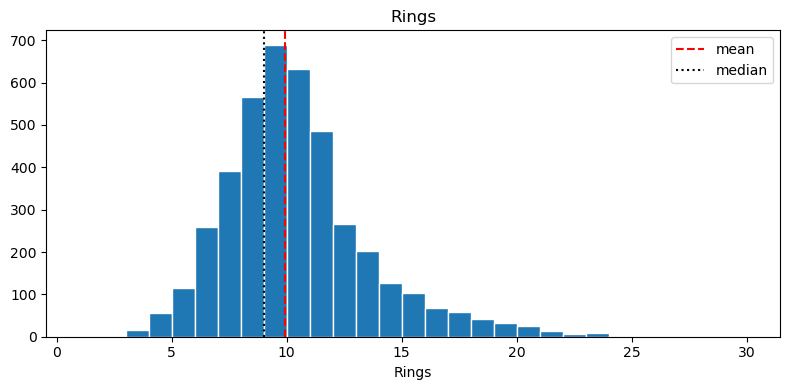

In [40]:
# target distribution
print(df["Rings"].describe())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["Rings"], bins=range(1, df["Rings"].max() + 2), edgecolor="white")
ax.axvline(df["Rings"].mean(), color="red", linestyle="--", label="mean")
ax.axvline(df["Rings"].median(), color="black", linestyle=":", label="median")
ax.set_title("Rings")
ax.set_xlabel("Rings")
ax.legend()
plt.tight_layout()
plt.show()

**Target (Rings)**

- Rings is only moderately right skewed. Since the skew is mild, we will predict Rings directly, without a log transform.
- As metric we will use MAE

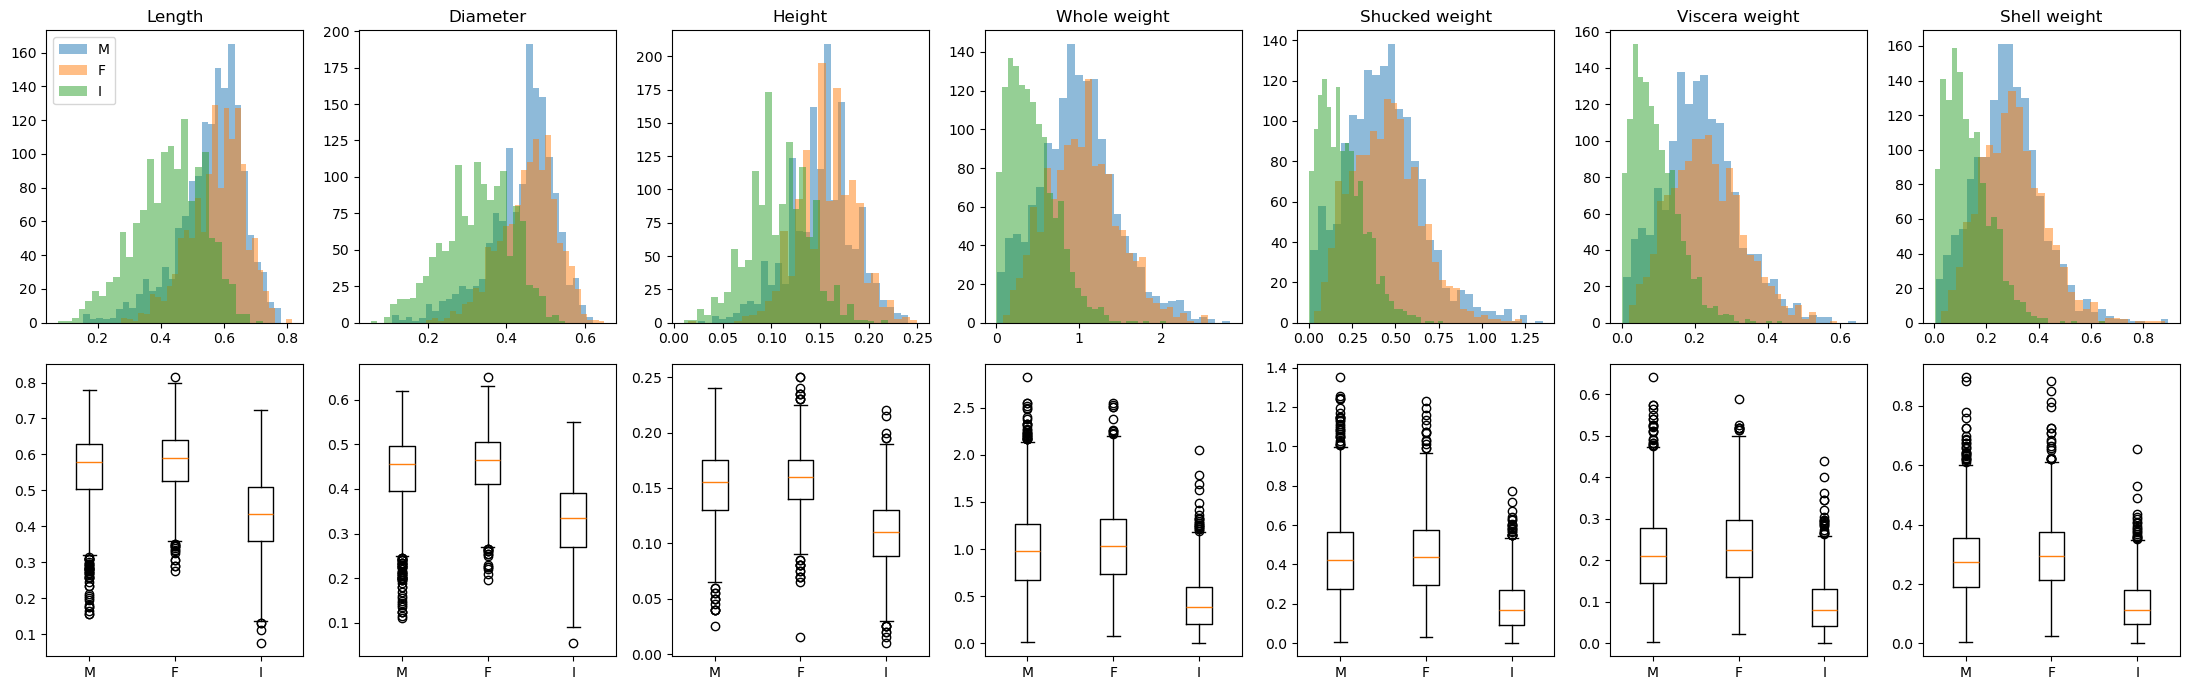

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight
Sex,,,,,,,
F,0.590,0.465,0.160,1.03625,0.44025,0.22400,0.29500
I,0.435,0.335,0.110,0.38400,0.16975,0.08050,0.11275
M,0.580,0.455,0.155,0.97500,0.42150,0.20975,0.27600


In [41]:
# feature distributions, split by Sex
features = df.select_dtypes("number").drop(columns="Rings").columns
sexes = ["M", "F", "I"]

fig, axes = plt.subplots(2, len(features), figsize=(22, 7))
for i, col in enumerate(features):
    for sex in sexes:
        axes[0, i].hist(df.loc[df["Sex"] == sex, col], bins=30, alpha=0.5, label=sex)
    axes[0, i].set_title(col)
    axes[1, i].boxplot([df.loc[df["Sex"] == sex, col] for sex in sexes])
    axes[1, i].set_xticks([1, 2, 3], sexes)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

df.groupby("Sex")[features].median()

**Features**

- Infants (I) are clearly smaller and lighter than adults. Male and females have similar distributions so we will only separate based on adult or not

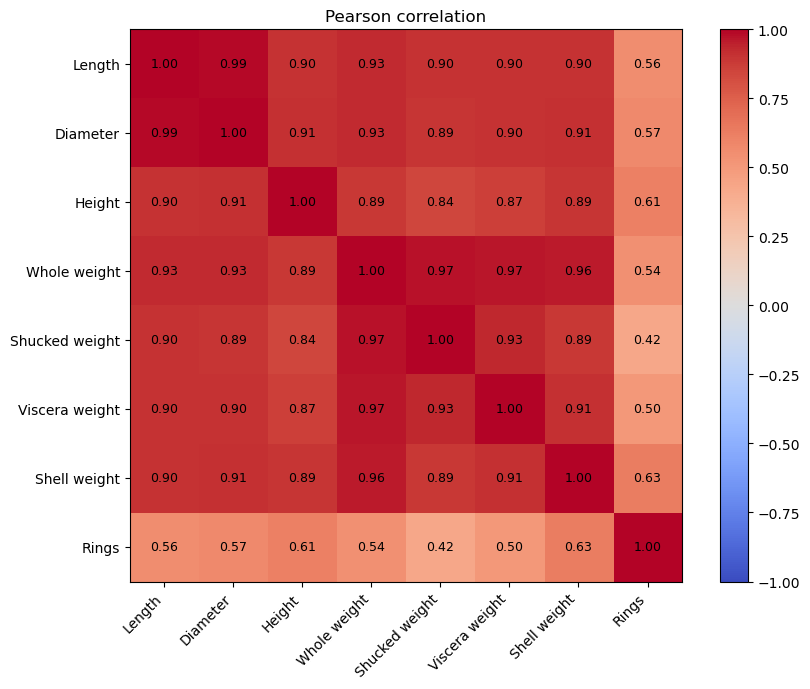

In [43]:
# correlation heatmap (features + target)
corr = df.select_dtypes("number").corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax)
ax.set_title("Pearson correlation")
plt.tight_layout()
plt.show()

**Correlations**

- The features are highly correlated with each other, so they carry largely redundant information. Depending on the model this will have different implications, i.e. linear models calls for regularization  or trimming the features while tree-based models see less impacts.
- Shell weight and Height have the highest correlationwith Rings, Shucked weight the least.

# Final Conclusions for modelling

- **Cleaning**: drop rows with impossible values (zero or negative measurements) and feature outliers beyond 3*IQR.
- **Target**: predict Rings directly, evaluated with MAE.
- **Sex**: encode it as a binary infant vs adult feature.
- **Numerical features**: keep them, but they are highly correlated.